# Phase 0-A: nuPlan NPZ Visualization

This notebook loads a pre-processed nuPlan `.npz` file and visualizes every field in BEV (bird's-eye view) to confirm semantics, coordinate systems, and data integrity before implementing the WOMD-to-npz converter.

## NPZ Field Reference

| Field | Shape | Description |
|---|---|---|
| `ego_agent_past` | (21, 14) | x, y, cos_h, sin_h, vx, vy, ax, ay, width, length, ego_type=1, 0, 0, 0 |
| `ego_current_state` | (16,) | x, y, cos_h, sin_h, vx, vy, ax, ay, steering_angle, yaw_rate, width, length, ego_type=1, 0, 0, 0 |
| `ego_agent_future` | (80, 3) | x, y, heading (relative to ego current pose) |
| `neighbor_agents_past` | (32, 21, 11) | x, y, cos_h, sin_h, vx, vy, width, length, type_veh, type_ped, type_cyc |
| `neighbor_agents_future` | (32, 80, 3) | x, y, heading (relative to ego current pose) |
| `lanes` | (70, 20, 12) | center_x, center_y, dx, dy, left_offset_x, left_offset_y, right_offset_x, right_offset_y, tl_green, tl_yellow, tl_red, tl_unknown |
| `lanes_speed_limit` | (70, 1) | speed limit in m/s |
| `lanes_has_speed_limit` | (70, 1) | boolean |
| `route_lanes` | (25, 20, 12) | same format as lanes |
| `route_lanes_speed_limit` | (25, 1) | speed limit in m/s |
| `route_lanes_has_speed_limit` | (25, 1) | boolean |
| `static_objects` | (5, 10) | x, y, cos_h, sin_h, width, length, type_czone_sign, type_barrier, type_cone, type_generic |

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import os

%matplotlib inline
plt.rcParams['figure.dpi'] = 120

In [70]:
# ============================================================
# >>> USER CONFIG: Set the path to an existing nuPlan npz file
# ============================================================
# NPZ_PATH = ""  # e.g. "/path/to/training_data/us-nv-las-vegas-strip_xxxx.npz"
# NPZ_PATH = "/Users/eddiesyn/code/GRID-Planner/samples/us-nv-las-vegas-strip_9d12248277a652fa.npz"
# NPZ_PATH = "/Users/eddiesyn/code/GRID-Planner/samples/us-pa-pittsburgh-hazelwood_ffe6c62ebf025de6.npz"
# NPZ_PATH = "/Users/eddiesyn/code/GRID-Planner/samples/sg-one-north_0597666a31f55707.npz"
NPZ_PATH = "/Users/eddiesyn/code/GRID-Planner/samples/us-pa-pittsburgh-hazelwood_ffffd77202f550a8.npz"

assert os.path.exists(NPZ_PATH), f"NPZ file not found: {NPZ_PATH}"
data = np.load(NPZ_PATH, allow_pickle=True)
print("Keys in npz:", list(data.keys()))
print(f"There are {len(data.keys())} keys in the npz file")
for k in sorted(data.keys()):
    v = data[k]
    print(f"  {k:30s}  shape={str(v.shape):20s}  dtype={v.dtype}")

Keys in npz: ['map_name', 'token', 'ego_agent_past', 'ego_current_state', 'ego_agent_future', 'neighbor_agents_past', 'neighbor_agents_future', 'static_objects', 'lanes', 'lanes_speed_limit', 'lanes_has_speed_limit', 'route_lanes', 'route_polygons', 'route_lanes_speed_limit', 'route_lanes_has_speed_limit', 'crosswalks']
There are 16 keys in the npz file
  crosswalks                      shape=(5, 10, 4)            dtype=float32
  ego_agent_future                shape=(80, 3)               dtype=float32
  ego_agent_past                  shape=(21, 14)              dtype=float32
  ego_current_state               shape=(16,)                 dtype=float32
  lanes                           shape=(70, 20, 12)          dtype=float32
  lanes_has_speed_limit           shape=(70, 1)               dtype=bool
  lanes_speed_limit               shape=(70, 1)               dtype=float32
  map_name                        shape=()                    dtype=<U26
  neighbor_agents_future          shape=(3

## Helper Functions

In [90]:
def draw_oriented_box(ax, x, y, cos_h, sin_h, width, length, color='blue', alpha=0.5, label=None):
    """Draw an oriented bounding box."""
    heading = np.arctan2(sin_h, cos_h)
    # corners in local frame (rear-axle centered)
    dx = length / 2
    dy = width / 2
    corners_local = np.array([
        [-dx, -dy],
        [ dx, -dy],
        [ dx,  dy],
        [-dx,  dy],
    ])
    cos_h_val, sin_h_val = np.cos(heading), np.sin(heading)
    R = np.array([[cos_h_val, -sin_h_val], [sin_h_val, cos_h_val]])
    corners_global = (R @ corners_local.T).T + np.array([x, y])
    polygon = plt.Polygon(corners_global, closed=True, facecolor=color, edgecolor='black', alpha=alpha, linewidth=0.5, label=label)
    ax.add_patch(polygon)
    # heading arrow
    arrow_len = length * 0.6
    ax.arrow(x, y, arrow_len * cos_h_val, arrow_len * sin_h_val,
             head_width=0.3, head_length=0.2, fc=color, ec=color, alpha=0.8)


def is_nonzero_agent(agent_past):
    """Check if an agent row is non-zero (i.e. real agent, not padding)."""
    return np.any(np.abs(agent_past) > 1e-6)


def get_agent_type_str(type_onehot):
    """Decode the agent type one-hot into a string."""
    if type_onehot[0] > 0.5:
        return 'vehicle'
    elif type_onehot[1] > 0.5:
        return 'pedestrian'
    elif type_onehot[2] > 0.5:
        return 'bicycle'
    return 'unknown'


AGENT_COLORS = {
    'vehicle': 'dodgerblue',
    'pedestrian': 'orange',
    'bicycle': 'limegreen',
    'unknown': 'gray',
}

TL_COLORS = {
    'green': '#00cc44',
    'yellow': '#ffcc00',
    'red': '#ff3333',
    'unknown': '#999999',
}

## 1. Ego Past Trajectory & Current State

In [72]:
ego_past[0]

array([-12.8084135 ,  -0.06277395,   0.9984773 ,   0.05516485,
         6.9546947 ,   0.33793825,  -0.26692042,  -0.7202208 ,
         2.297     ,   5.176     ,   1.        ,   0.        ,
         0.        ,   0.        ], dtype=float32)

In [91]:
ego_past = data['ego_agent_past']       # (21, 14), history 21帧 (2.0s, 10Hz), 14 维度特征记录
ego_current = data['ego_current_state']  # (16,) current 有16个维度

# history
# x, y, cos_h, sin_h, vx, vy, ax, ay, width, length, ego_type, 0, 0, 0

# current
# x, y, cos_h, sin_h, vx, vy, ax, ay, steering_angle, yaw_rate, width, length, ego_type, 0, 0, 0

print("=== ego_agent_past ===")
print(f"  Shape: {ego_past.shape}")
print(f"  Last frame (current): x={ego_past[-1,0]:.3f}, y={ego_past[-1,1]:.3f}, "
      f"cos_h={ego_past[-1,2]:.3f}, sin_h={ego_past[-1,3]:.3f}")
print(f"  First frame (oldest): x={ego_past[0,0]:.3f}, y={ego_past[0,1]:.3f}")
print(f"  Velocity range: vx=[{ego_past[:,4].min():.2f}, {ego_past[:,4].max():.2f}], "
      f"vy=[{ego_past[:,5].min():.2f}, {ego_past[:,5].max():.2f}]")
print(f"  Width={ego_past[-1,8]:.2f}, Length={ego_past[-1,9]:.2f}")
print(f"  ego_type (dim 10) = {ego_past[-1, 10]:.0f}")
print()
print("=== ego_current_state ===")
print(f"  Shape: {ego_current.shape}")
print(f"  x={ego_current[0]:.3f}, y={ego_current[1]:.3f}, "
      f"cos_h={ego_current[2]:.3f}, sin_h={ego_current[3]:.3f}")
print(f"  vx={ego_current[4]:.3f}, vy={ego_current[5]:.3f}, "
      f"ax={ego_current[6]:.3f}, ay={ego_current[7]:.3f}")
print(f"  steering_angle={ego_current[8]:.4f}, yaw_rate={ego_current[9]:.4f}")
print(f"  Width={ego_current[10]:.2f}, Length={ego_current[11]:.2f}")
print(f"  ego_type (dim 12)={ego_current[12]:.0f}")
print()
print("VERIFICATION: ego current position should be near origin (ego-centric frame):")
print(f"  |x|={abs(ego_current[0]):.4f}, |y|={abs(ego_current[1]):.4f}")

=== ego_agent_past ===
  Shape: (21, 14)
  Last frame (current): x=0.000, y=0.000, cos_h=1.000, sin_h=-0.000
  First frame (oldest): x=-12.808, y=-0.063
  Velocity range: vx=[6.18, 6.95], vy=[-0.20, 0.34]
  Width=2.30, Length=5.18
  ego_type (dim 10) = 1

=== ego_current_state ===
  Shape: (16,)
  x=0.000, y=0.000, cos_h=1.000, sin_h=-0.000
  vx=6.175, vy=-0.080, ax=-0.705, ay=0.357
  steering_angle=0.0217, yaw_rate=0.0434
  Width=2.30, Length=5.18
  ego_type (dim 12)=1

VERIFICATION: ego current position should be near origin (ego-centric frame):
  |x|=0.0000, |y|=0.0000


/var/folders/ws/p1f240tx6w347457j6mx1yxw0000gn/T/ipykernel_56778/4272503834.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Blues')


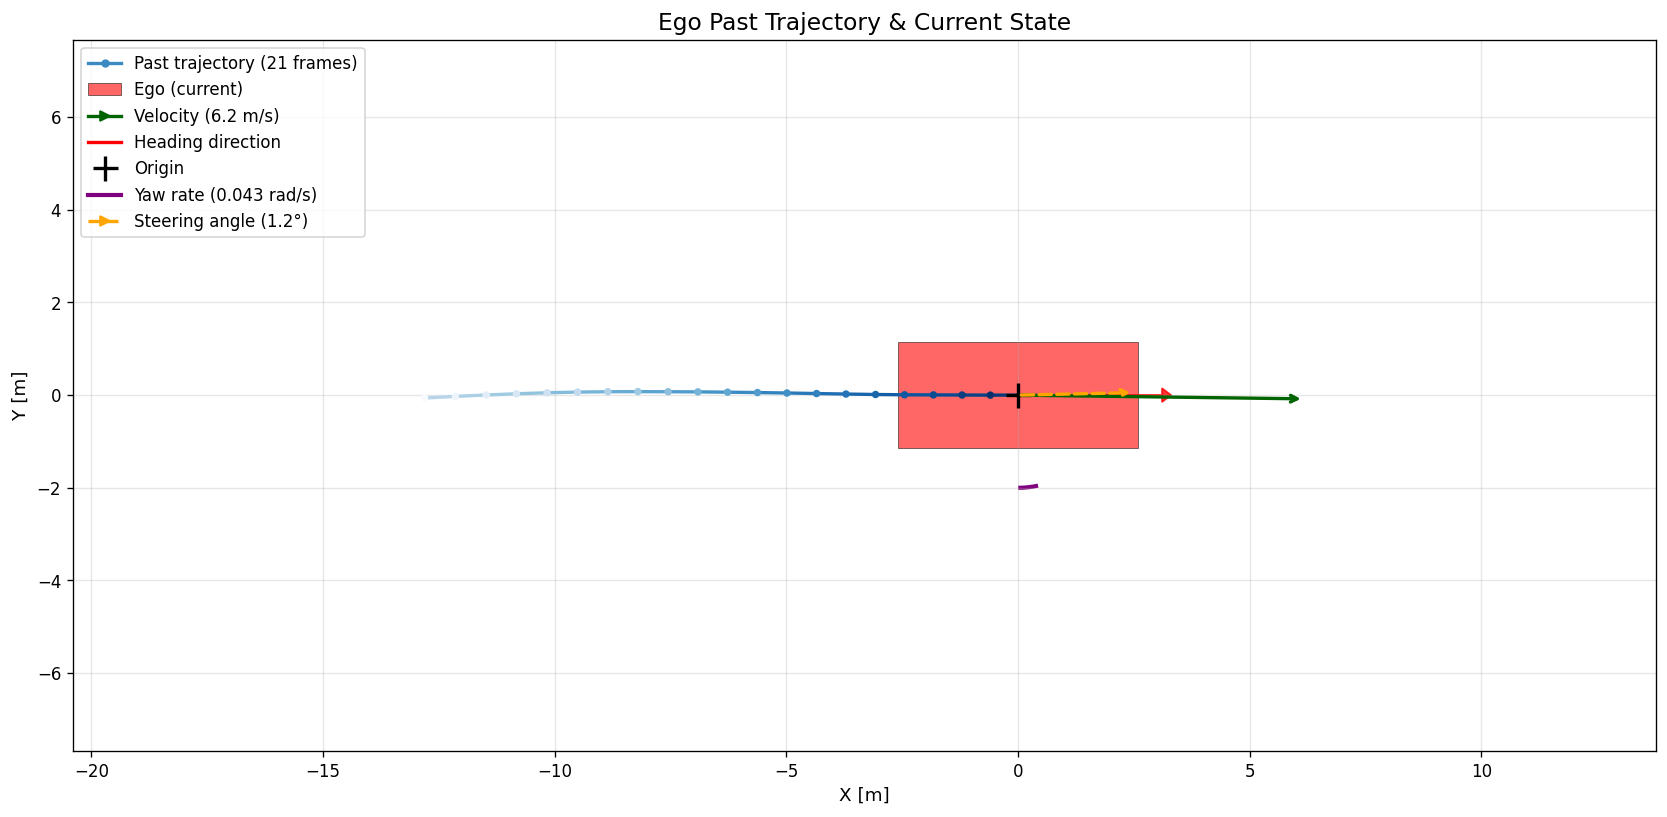

Past trajectory: 21 frames
  x range: [-12.808, 0.000]
  y range: [-0.063, 0.076]

Current state kinematics:
  heading:        -0.0°
  speed:          6.18 m/s  (vx=6.18, vy=-0.08)
  steering_angle: 0.0217 rad (1.2°)
  yaw_rate:       0.0434 rad/s
  (yaw_rate = Δheading/Δt, steering = arctan(yaw_rate × wheelbase / |vx|))


In [94]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('Ego Past Trajectory & Current State', fontsize=14)

n_past = ego_past.shape[0]
cmap = cm.get_cmap('Blues')

for i in range(n_past - 1):
    color = cmap(0.3 + 0.7 * i / (n_past - 1))
    ax.plot([ego_past[i, 0], ego_past[i+1, 0]],
            [ego_past[i, 1], ego_past[i+1, 1]],
            color=color, linewidth=2)

ax.scatter(ego_past[:-1, 0], ego_past[:-1, 1], c=np.arange(n_past-1), cmap='Blues',
           s=20, zorder=5, edgecolors='none')
ax.plot([], [], color=cmap(0.65), linewidth=2, marker='o', markersize=4,
        label=f'Past trajectory ({n_past} frames)')

# Current state box
draw_oriented_box(ax, ego_current[0], ego_current[1],
                  ego_current[2], ego_current[3],
                  ego_current[10], ego_current[11],
                  color='red', alpha=0.6, label='Ego (current)')

# Velocity arrow (drawn as explicit arrow so length is visible)
v_scale = 1.0  # 1 m/s = 1 m on plot
vx, vy = ego_current[4], ego_current[5]
ax.annotate('', xy=(ego_current[0] + vx * v_scale, ego_current[1] + vy * v_scale),
            xytext=(ego_current[0], ego_current[1]),
            arrowprops=dict(arrowstyle='->', color='darkgreen', lw=2))
ax.plot([], [], '->', color='darkgreen', linewidth=2,
        label=f'Velocity ({np.sqrt(vx**2+vy**2):.1f} m/s)')
ax.plot([], [], '-', color='red', linewidth=2, label='Heading direction')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='Origin')

# Steering angle & yaw rate visualization
steering_angle = ego_current[8]
yaw_rate = ego_current[9]
heading = np.arctan2(ego_current[3], ego_current[2])
speed = np.sqrt(vx**2 + vy**2)

# Draw yaw rate as a curved arrow (arc showing turning tendency)
if abs(yaw_rate) > 1e-4:
    arc_radius = 2.0
    arc_start = np.degrees(heading) - 90  # matplotlib Arc uses degrees
    arc_extent = np.degrees(yaw_rate) * 5  # exaggerate for visibility
    arc_extent = np.clip(arc_extent, -60, 60)
    from matplotlib.patches import Arc, FancyArrowPatch
    arc = Arc((ego_current[0], ego_current[1]), arc_radius*2, arc_radius*2,
              angle=0, theta1=arc_start, theta2=arc_start + arc_extent,
              color='purple', linewidth=2.5, linestyle='-')
    ax.add_patch(arc)
ax.plot([], [], '-', color='purple', linewidth=2.5,
        label=f'Yaw rate ({yaw_rate:.3f} rad/s)')

# Draw steering angle as a rotated line from ego center
if abs(steering_angle) > 1e-4:
    steer_len = 2.5
    steer_heading = heading + steering_angle
    sx = ego_current[0] + steer_len * np.cos(steer_heading)
    sy = ego_current[1] + steer_len * np.sin(steer_heading)
    ax.annotate('', xy=(sx, sy), xytext=(ego_current[0], ego_current[1]),
                arrowprops=dict(arrowstyle='->', color='orange', lw=2, linestyle='--'))
ax.plot([], [], '-->', color='orange', linewidth=2,
        label=f'Steering angle ({np.degrees(steering_angle):.1f}°)')

# Auto-zoom: include velocity arrow endpoint
vel_end_x = ego_current[0] + vx * v_scale
vel_end_y = ego_current[1] + vy * v_scale
all_x = np.concatenate([ego_past[:, 0], [ego_current[0], vel_end_x]])
all_y = np.concatenate([ego_past[:, 1], [ego_current[1], vel_end_y]])
margin = max(5.0, (all_x.max() - all_x.min()) * 0.4, (all_y.max() - all_y.min()) * 0.4)
ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
ax.set_ylim(all_y.min() - margin, all_y.max() + margin)

ax.set_xlabel('X [m]', fontsize=11)
ax.set_ylabel('Y [m]', fontsize=11)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Past trajectory: {n_past} frames")
print(f"  x range: [{ego_past[:, 0].min():.3f}, {ego_past[:, 0].max():.3f}]")
print(f"  y range: [{ego_past[:, 1].min():.3f}, {ego_past[:, 1].max():.3f}]")
print(f"\nCurrent state kinematics:")
print(f"  heading:        {np.degrees(heading):.1f}°")
print(f"  speed:          {speed:.2f} m/s  (vx={vx:.2f}, vy={vy:.2f})")
print(f"  steering_angle: {steering_angle:.4f} rad ({np.degrees(steering_angle):.1f}°)")
print(f"  yaw_rate:       {yaw_rate:.4f} rad/s")
print(f"  (yaw_rate = Δheading/Δt, steering = arctan(yaw_rate × wheelbase / |vx|))")

## 2. Ego Future Trajectory (Ground Truth)

In [95]:
ego_future = data['ego_agent_future']  # (80, 3): x, y, heading

print("=== ego_agent_future ===")
print(f"  Shape: {ego_future.shape}")
print(f"  First future step: x={ego_future[0,0]:.3f}, y={ego_future[0,1]:.3f}, heading={ego_future[0,2]:.3f}")
print(f"  Last future step:  x={ego_future[-1,0]:.3f}, y={ego_future[-1,1]:.3f}, heading={ego_future[-1,2]:.3f}")
print(f"  Total displacement: {np.sqrt(ego_future[-1,0]**2 + ego_future[-1,1]**2):.2f} m over 8 seconds")

=== ego_agent_future ===
  Shape: (80, 3)
  First future step: x=0.592, y=0.004, heading=0.004
  Last future step:  x=15.788, y=1.258, heading=0.136
  Total displacement: 15.84 m over 8 seconds


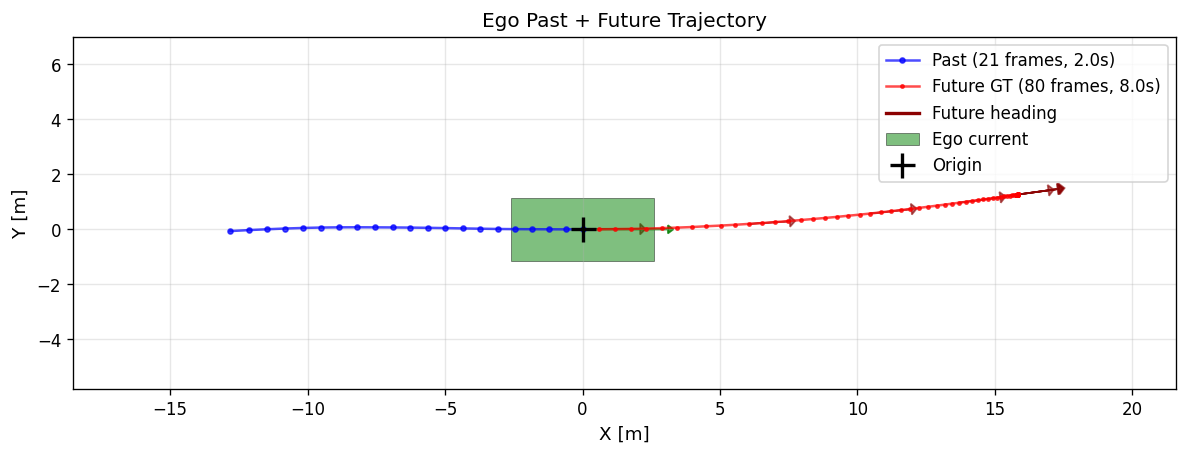

In [98]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title('Ego Past + Future Trajectory')

# Past trajectory
ax.plot(ego_past[:, 0], ego_past[:, 1], 'b-o', markersize=3, linewidth=1.5,
        label=f'Past ({ego_past.shape[0]} frames, 2.0s)', alpha=0.7)

# Future trajectory
ax.plot(ego_future[:, 0], ego_future[:, 1], 'r-o', markersize=2, linewidth=1.5,
        label=f'Future GT ({ego_future.shape[0]} frames, 8.0s)', alpha=0.7)

# Heading arrows along future (every 10 frames)
for i in range(0, ego_future.shape[0], 10):
    h = ego_future[i, 2]
    ax.arrow(ego_future[i, 0], ego_future[i, 1],
             1.5 * np.cos(h), 1.5 * np.sin(h),
             head_width=0.4, head_length=0.2, fc='darkred', ec='darkred', alpha=0.6)
ax.plot([], [], '-', color='darkred', linewidth=2, label='Future heading')

# Current ego
draw_oriented_box(ax, ego_current[0], ego_current[1],
                  ego_current[2], ego_current[3],
                  ego_current[10], ego_current[11],
                  color='green', alpha=0.5, label='Ego current')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='Origin')

# Auto-zoom to fit past + future with generous padding
all_x = np.concatenate([ego_past[:, 0], ego_future[:, 0]])
all_y = np.concatenate([ego_past[:, 1], ego_future[:, 1]])
margin = max(5.0, (all_x.max() - all_x.min()) * 0.2, (all_y.max() - all_y.min()) * 0.2)
ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
ax.set_ylim(all_y.min() - margin, all_y.max() + margin)

ax.set_xlabel('X [m]', fontsize=11)
ax.set_ylabel('Y [m]', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Neighbor Agents (Past & Future)

In [99]:
# neighbor agents 最多 32个
# 按离 ego 的距离排序
# 行人 + 自行车最多选 max_ped_bike=10 个
# 车辆全选
# 如果总数不足 32 则补更多行人/自行车
# 最终按距离排序取最近的 32 个
# 11维度：x, y, cos_h, sin_h, vx, vy, width, length, type_veh, type_ped, type_cyc

neighbor_past = data['neighbor_agents_past']      # (32, 21, 11)
neighbor_future = data['neighbor_agents_future']  # (32, 80, 3)

print("=== neighbor_agents_past ===")
print(f"  Shape: {neighbor_past.shape}")
print(f"  Dims: x, y, cos_h, sin_h, vx, vy, width, length, type_veh, type_ped, type_cyc")

# Count real agents
n_real = sum(1 for i in range(neighbor_past.shape[0]) if is_nonzero_agent(neighbor_past[i, -1]))
print(f"  Real agents (non-zero at current frame): {n_real}/{neighbor_past.shape[0]}")

# Count by type
type_counts = {'vehicle': 0, 'pedestrian': 0, 'bicycle': 0, 'unknown': 0}
for i in range(neighbor_past.shape[0]):
    if is_nonzero_agent(neighbor_past[i, -1]):
        t = get_agent_type_str(neighbor_past[i, -1, 8:11])
        type_counts[t] += 1
print(f"  Type distribution: {type_counts}")

print()
print("=== neighbor_agents_future ===")
print(f"  Shape: {neighbor_future.shape}")
print(f"  Dims: x, y, heading")

=== neighbor_agents_past ===
  Shape: (32, 21, 11)
  Dims: x, y, cos_h, sin_h, vx, vy, width, length, type_veh, type_ped, type_cyc
  Real agents (non-zero at current frame): 16/32
  Type distribution: {'vehicle': 16, 'pedestrian': 0, 'bicycle': 0, 'unknown': 0}

=== neighbor_agents_future ===
  Shape: (32, 80, 3)
  Dims: x, y, heading


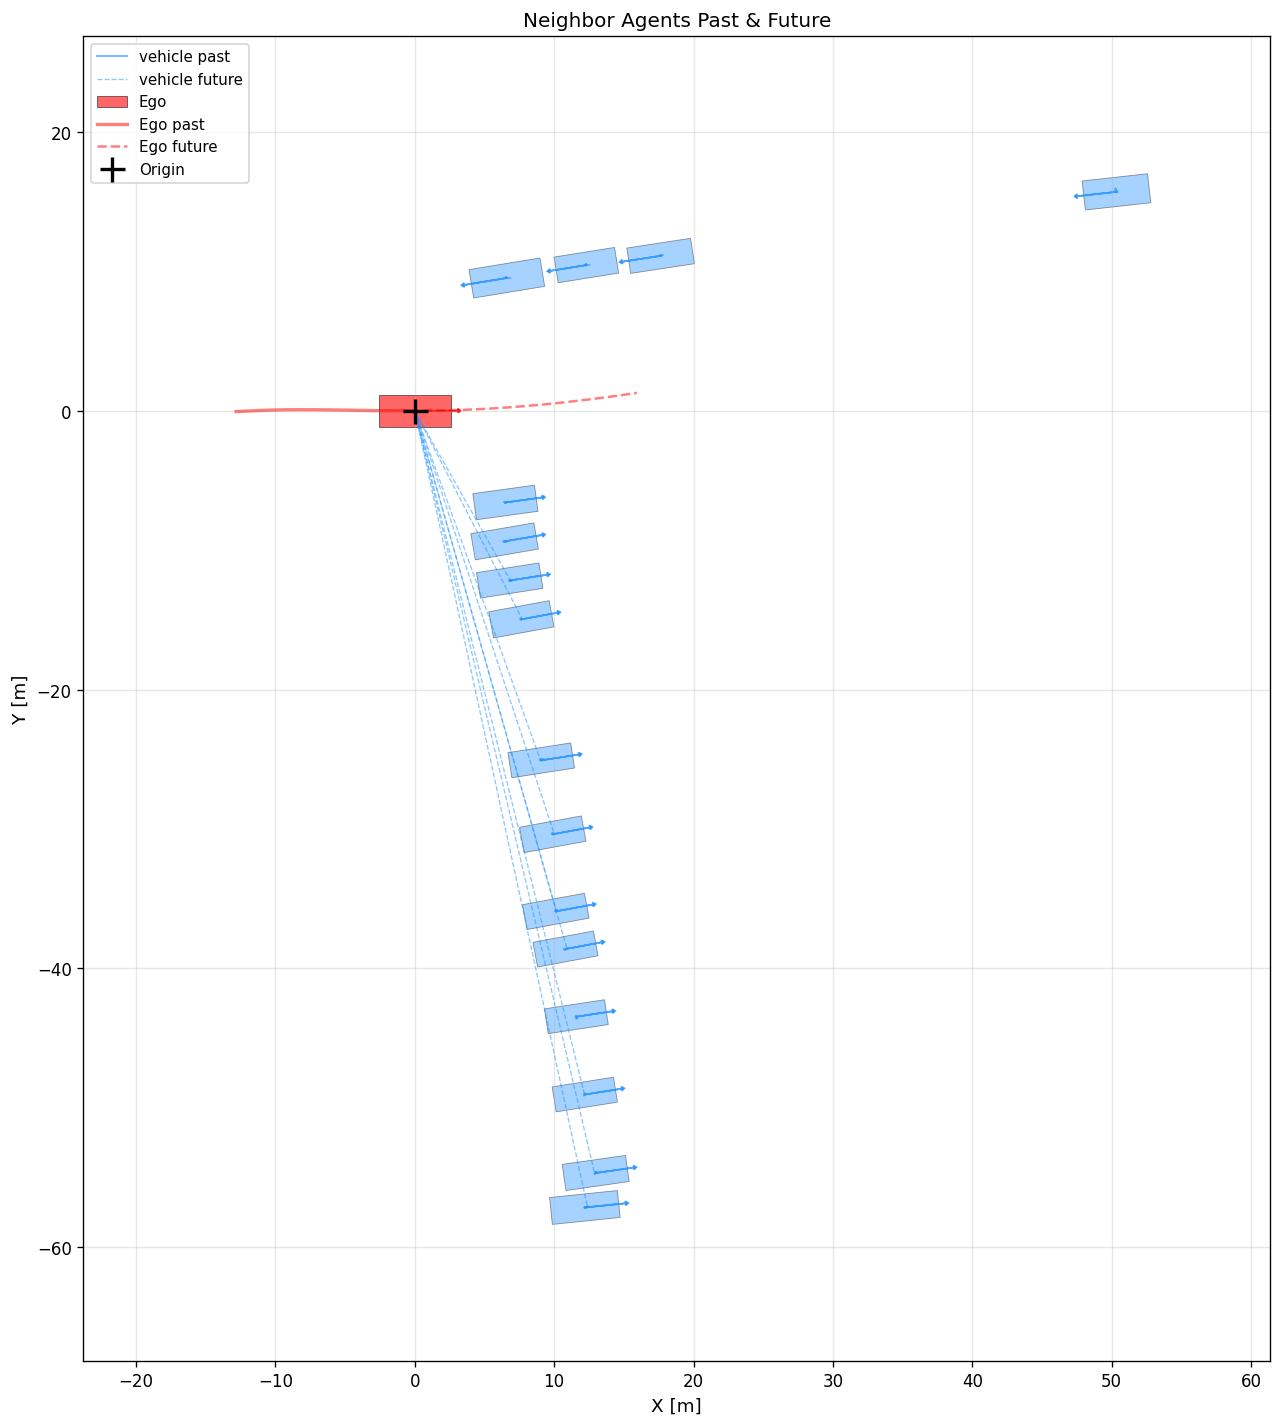

In [101]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
ax.set_aspect('equal')
ax.set_title('Neighbor Agents Past & Future')

legend_added = set()

for i in range(neighbor_past.shape[0]):
    # Skip zero-padded agents
    if not is_nonzero_agent(neighbor_past[i, -1]):
        continue
    
    agent_type = get_agent_type_str(neighbor_past[i, -1, 8:11])
    color = AGENT_COLORS[agent_type]
    
    # Past trajectory
    past_x = neighbor_past[i, :, 0]
    past_y = neighbor_past[i, :, 1]
    lbl_past = f'{agent_type} past' if agent_type not in legend_added else None
    ax.plot(past_x, past_y, '-', color=color, linewidth=1.2, alpha=0.6, label=lbl_past)
    
    # Current bounding box
    cur = neighbor_past[i, -1]
    draw_oriented_box(ax, cur[0], cur[1], cur[2], cur[3],
                      cur[6], cur[7], color=color, alpha=0.4)
    
    # Future trajectory (dashed)
    if is_nonzero_agent(neighbor_future[i, 0]):
        fut_x = neighbor_future[i, :, 0]
        fut_y = neighbor_future[i, :, 1]
        ax.plot(fut_x, fut_y, '--', color=color, linewidth=0.8, alpha=0.5)
    
    legend_added.add(agent_type)

# Add future trajectory legend entries (dashed style)
for atype, acolor in AGENT_COLORS.items():
    if atype in legend_added:
        ax.plot([], [], '--', color=acolor, linewidth=0.8, alpha=0.5, label=f'{atype} future')

# Ego
draw_oriented_box(ax, ego_current[0], ego_current[1],
                  ego_current[2], ego_current[3],
                  ego_current[10], ego_current[11],
                  color='red', alpha=0.6, label='Ego')
ax.plot(ego_past[:, 0], ego_past[:, 1], 'r-', linewidth=2, alpha=0.5, label='Ego past')
ax.plot(ego_future[:, 0], ego_future[:, 1], 'r--', linewidth=1.5, alpha=0.5, label='Ego future')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='Origin')

# Auto-zoom to fit all agents with padding
all_x = list(ego_past[:, 0]) + list(ego_future[:, 0])
all_y = list(ego_past[:, 1]) + list(ego_future[:, 1])
for i in range(neighbor_past.shape[0]):
    if is_nonzero_agent(neighbor_past[i, -1]):
        all_x.extend(neighbor_past[i, :, 0])
        all_y.extend(neighbor_past[i, :, 1])
        if is_nonzero_agent(neighbor_future[i, 0]):
            all_x.extend(neighbor_future[i, :, 0])
            all_y.extend(neighbor_future[i, :, 1])
all_x, all_y = np.array(all_x), np.array(all_y)
margin = max(10.0, (all_x.max() - all_x.min()) * 0.15, (all_y.max() - all_y.min()) * 0.15)
ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
ax.set_ylim(all_y.min() - margin, all_y.max() + margin)

ax.set_xlabel('X [m]', fontsize=11)
ax.set_ylabel('Y [m]', fontsize=11)
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Lanes (Center, Left/Right Boundary, Traffic Light)

In [102]:
# 70 = max_elements['LANE']，即最多提取 70 条 lane（在 ego 周围 100m 范围内查询，按距离排序取最近的 70 条，不足则 0 填充）
# 20 = max_points['LANE']，即每条 lane 最多 20 个插值点（对原始 lane polyline 做等距插值/截断到固定 20 个点，不足则 0 填充）
# 12 = 每个点的特征维度
# - center_x, center_y: 中心线点的 x y 坐标（ego-centric）
# - dx, dy: 指向下一个点的方向向量 x y（polyline[i+1] - polyline[i]）
# - left_offset_x, left_offset_y: 左边界偏移 x（left_boundary[i] - polyline[i]）左边界偏移 y
# - right_offset_x, right_offset_y: 右边界偏移 x（right_boundary[i] - polyline[i]）右边界偏移 y
# - tl_green, tl_yellow, tl_red, tl_unknown: 绿,黄,红灯，未知，one-hot

lanes = data['lanes']                        # (70, 20, 12)
lanes_speed_limit = data['lanes_speed_limit'] # (70, 1)  # 该 lane 的限速值，单位 m/s。如果没有限速信息，值为 0.0。
lanes_has_speed_limit = data['lanes_has_speed_limit']  # (70, 1)  # 表示该 lane 是否有限速信息。nuPlan 地图中有些 lane 有限速标注，有些没有

print("=== lanes ===")
print(f"  Shape: {lanes.shape}")
print(f"  Dims per point: center_x(0), center_y(1), dx(2), dy(3), ")
print(f"    left_offset_x(4), left_offset_y(5), right_offset_x(6), right_offset_y(7), ")
print(f"    tl_green(8), tl_yellow(9), tl_red(10), tl_unknown(11)")

# Count non-zero lanes
n_lanes = sum(1 for i in range(lanes.shape[0]) if np.any(np.abs(lanes[i]) > 1e-6))
print(f"  Real lanes: {n_lanes}/{lanes.shape[0]}")

# Check traffic light states
tl_stats = {'green': 0, 'yellow': 0, 'red': 0, 'unknown': 0, 'none': 0}
for i in range(lanes.shape[0]):
    if np.any(np.abs(lanes[i]) > 1e-6):
        tl = lanes[i, 0, 8:12]  # traffic light at first point
        if tl[0] > 0.5:
            tl_stats['green'] += 1
        elif tl[1] > 0.5:
            tl_stats['yellow'] += 1
        elif tl[2] > 0.5:
            tl_stats['red'] += 1
        elif tl[3] > 0.5:
            tl_stats['unknown'] += 1
        else:
            tl_stats['none'] += 1
print(f"  Traffic light states: {tl_stats}")
has_sl = lanes_has_speed_limit.flatten()
if has_sl.any():
    sl_vals = lanes_speed_limit[has_sl]
    print(f"  Speed limit range: [{sl_vals.min():.1f}, {sl_vals.max():.1f}] m/s  ({has_sl.sum()}/{len(has_sl)} lanes have speed limit)")
else:
    print(f"  Speed limit: no lanes have speed limit data in this sample")

# Verify boundary offset interpretation
sample_lane_idx = 0
for i in range(lanes.shape[0]):
    if np.any(np.abs(lanes[i]) > 1e-6):
        sample_lane_idx = i
        break
sl = lanes[sample_lane_idx]
print(f"\n  Sample lane {sample_lane_idx} first point:")
print(f"    center=({sl[0,0]:.2f}, {sl[0,1]:.2f})")
print(f"    direction=(dx={sl[0,2]:.3f}, dy={sl[0,3]:.3f})")
print(f"    left_offset=({sl[0,4]:.2f}, {sl[0,5]:.2f})")
print(f"    right_offset=({sl[0,6]:.2f}, {sl[0,7]:.2f})")
print(f"    => left_boundary = center + left_offset = ({sl[0,0]+sl[0,4]:.2f}, {sl[0,1]+sl[0,5]:.2f})")
print(f"    => right_boundary = center + right_offset = ({sl[0,0]+sl[0,6]:.2f}, {sl[0,1]+sl[0,7]:.2f})")
print(f"    left-right distance: {np.sqrt((sl[0,4]-sl[0,6])**2 + (sl[0,5]-sl[0,7])**2):.2f} m (expect ~3-4m for a lane)")

=== lanes ===
  Shape: (70, 20, 12)
  Dims per point: center_x(0), center_y(1), dx(2), dy(3), 
    left_offset_x(4), left_offset_y(5), right_offset_x(6), right_offset_y(7), 
    tl_green(8), tl_yellow(9), tl_red(10), tl_unknown(11)
  Real lanes: 40/70
  Traffic light states: {'green': 0, 'yellow': 0, 'red': 0, 'unknown': 40, 'none': 0}
  Speed limit range: [11.2, 11.2] m/s  (40/70 lanes have speed limit)

  Sample lane 0 first point:
    center=(0.84, -5.60)
    direction=(dx=-0.165, dy=1.129)
    left_offset=(-1.69, 0.55)
    right_offset=(1.49, 1.04)
    => left_boundary = center + left_offset = (-0.85, -5.05)
    => right_boundary = center + right_offset = (2.33, -4.56)
    left-right distance: 3.22 m (expect ~3-4m for a lane)


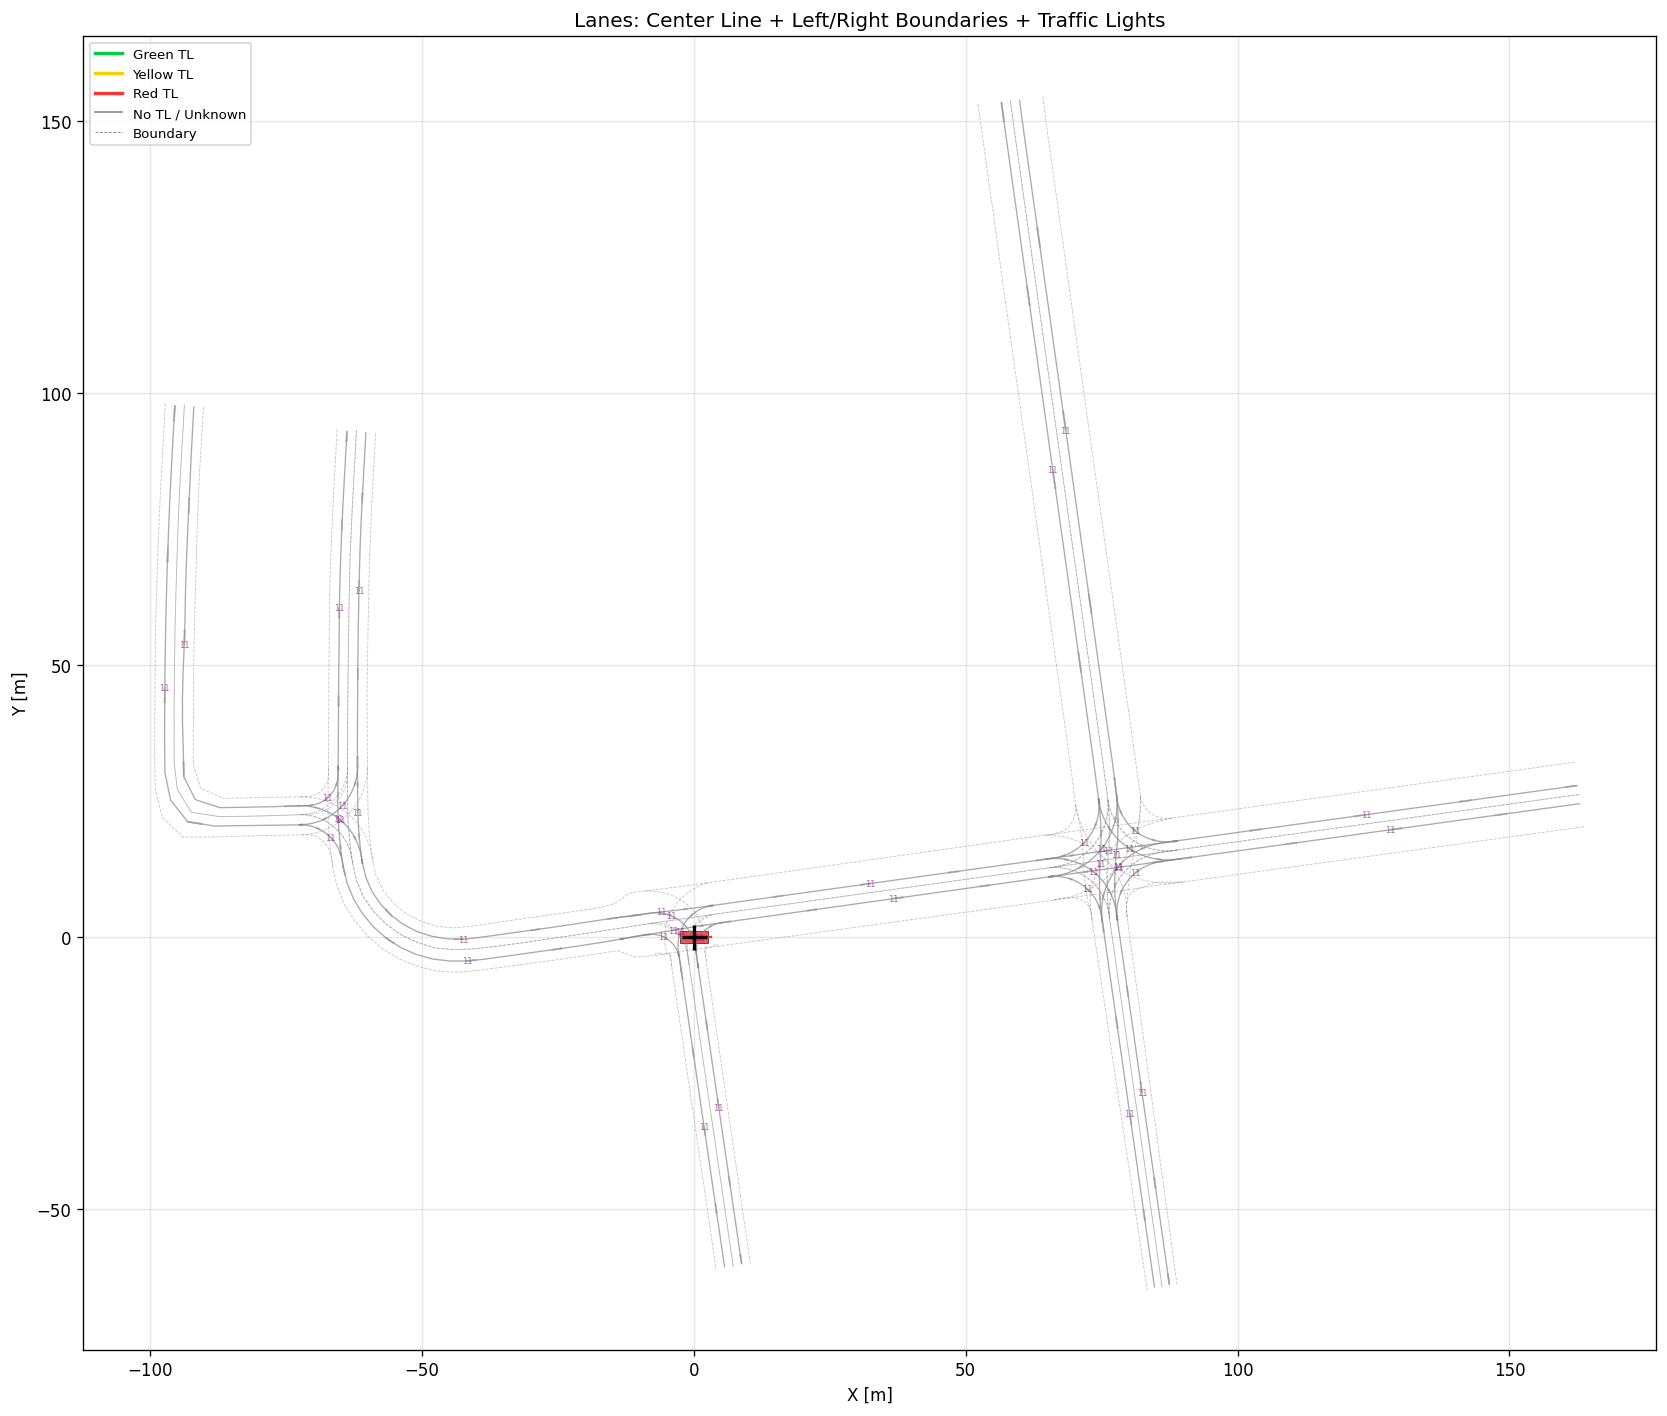

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('Lanes: Center Line + Left/Right Boundaries + Traffic Lights')

for i in range(lanes.shape[0]):
    lane = lanes[i]
    if not np.any(np.abs(lane) > 1e-6):
        continue
    
    center_x = lane[:, 0]
    center_y = lane[:, 1]
    
    # Left and right boundaries (center + offset)
    left_x = center_x + lane[:, 4]
    left_y = center_y + lane[:, 5]
    right_x = center_x + lane[:, 6]
    right_y = center_y + lane[:, 7]
    
    # Determine traffic light color for this lane
    tl = lane[0, 8:12]
    if tl[0] > 0.5:
        lane_color = TL_COLORS['green']
        lw = 2.0
    elif tl[1] > 0.5:
        lane_color = TL_COLORS['yellow']
        lw = 2.0
    elif tl[2] > 0.5:
        lane_color = TL_COLORS['red']
        lw = 2.0
    else:
        lane_color = '#888888'
        lw = 0.8
    
    # Center line
    ax.plot(center_x, center_y, '-', color=lane_color, linewidth=lw, alpha=0.7)
    
    # Left boundary (dashed)
    ax.plot(left_x, left_y, '--', color=lane_color, linewidth=0.5, alpha=0.5)
    
    # Right boundary (dashed)
    ax.plot(right_x, right_y, '--', color=lane_color, linewidth=0.5, alpha=0.5)
    
    # Direction arrows (every 5 points)
    for j in range(0, lane.shape[0], 5):
        dx, dy = lane[j, 2], lane[j, 3]
        if abs(dx) + abs(dy) > 1e-6:
            ax.arrow(center_x[j], center_y[j], dx * 0.5, dy * 0.5,
                     head_width=0.3, head_length=0.15, fc=lane_color, ec=lane_color, alpha=0.4)

# Speed limit annotations
for i in range(lanes.shape[0]):
    if lanes_has_speed_limit[i] and np.any(np.abs(lanes[i]) > 1e-6):
        mid = lanes.shape[1] // 2
        ax.annotate(f"{lanes_speed_limit[i,0]:.0f}",
                    xy=(lanes[i, mid, 0], lanes[i, mid, 1]),
                    fontsize=5, color='purple', alpha=0.6,
                    ha='center', va='center')

# Ego
draw_oriented_box(ax, ego_current[0], ego_current[1],
                  ego_current[2], ego_current[3],
                  ego_current[10], ego_current[11],
                  color='red', alpha=0.7, label='Ego')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')

# Legend for traffic lights
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color=TL_COLORS['green'], linewidth=2, label='Green TL'),
    Line2D([0], [0], color=TL_COLORS['yellow'], linewidth=2, label='Yellow TL'),
    Line2D([0], [0], color=TL_COLORS['red'], linewidth=2, label='Red TL'),
    Line2D([0], [0], color='#888888', linewidth=1, label='No TL / Unknown'),
    Line2D([0], [0], color='#888888', linewidth=0.5, linestyle='--', label='Boundary'),
]
ax.legend(handles=legend_elements, fontsize=8, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Route Lanes

In [81]:
# 上面那个lane：ego 周围 100m 范围内所有最近的 lane
# 这里的route_lanes: 其中位于 ego 规划路线（route）上的 lane, 最大数量为25（从 lanes 里筛选 lane_on_route[i] == True 的子集）
# 由于遍历顺序继承自 lanes 的顺序（按离 ego 距离排序），所以截断时保留的是离 ego 最近的 25 条 route lane，更远的会被丢弃。

route_lanes = data['route_lanes']  # (25, 20, 12)
route_speed = data['route_lanes_speed_limit']  # (25, 1)
route_has_speed = data['route_lanes_has_speed_limit']  # (25, 1)

n_route = sum(1 for i in range(route_lanes.shape[0]) if np.any(np.abs(route_lanes[i]) > 1e-6))
print(f"=== route_lanes ===")
print(f"  Shape: {route_lanes.shape}")
print(f"  Real route lanes: {n_route}/{route_lanes.shape[0]}")

=== route_lanes ===
  Shape: (25, 20, 12)
  Real route lanes: 7/25


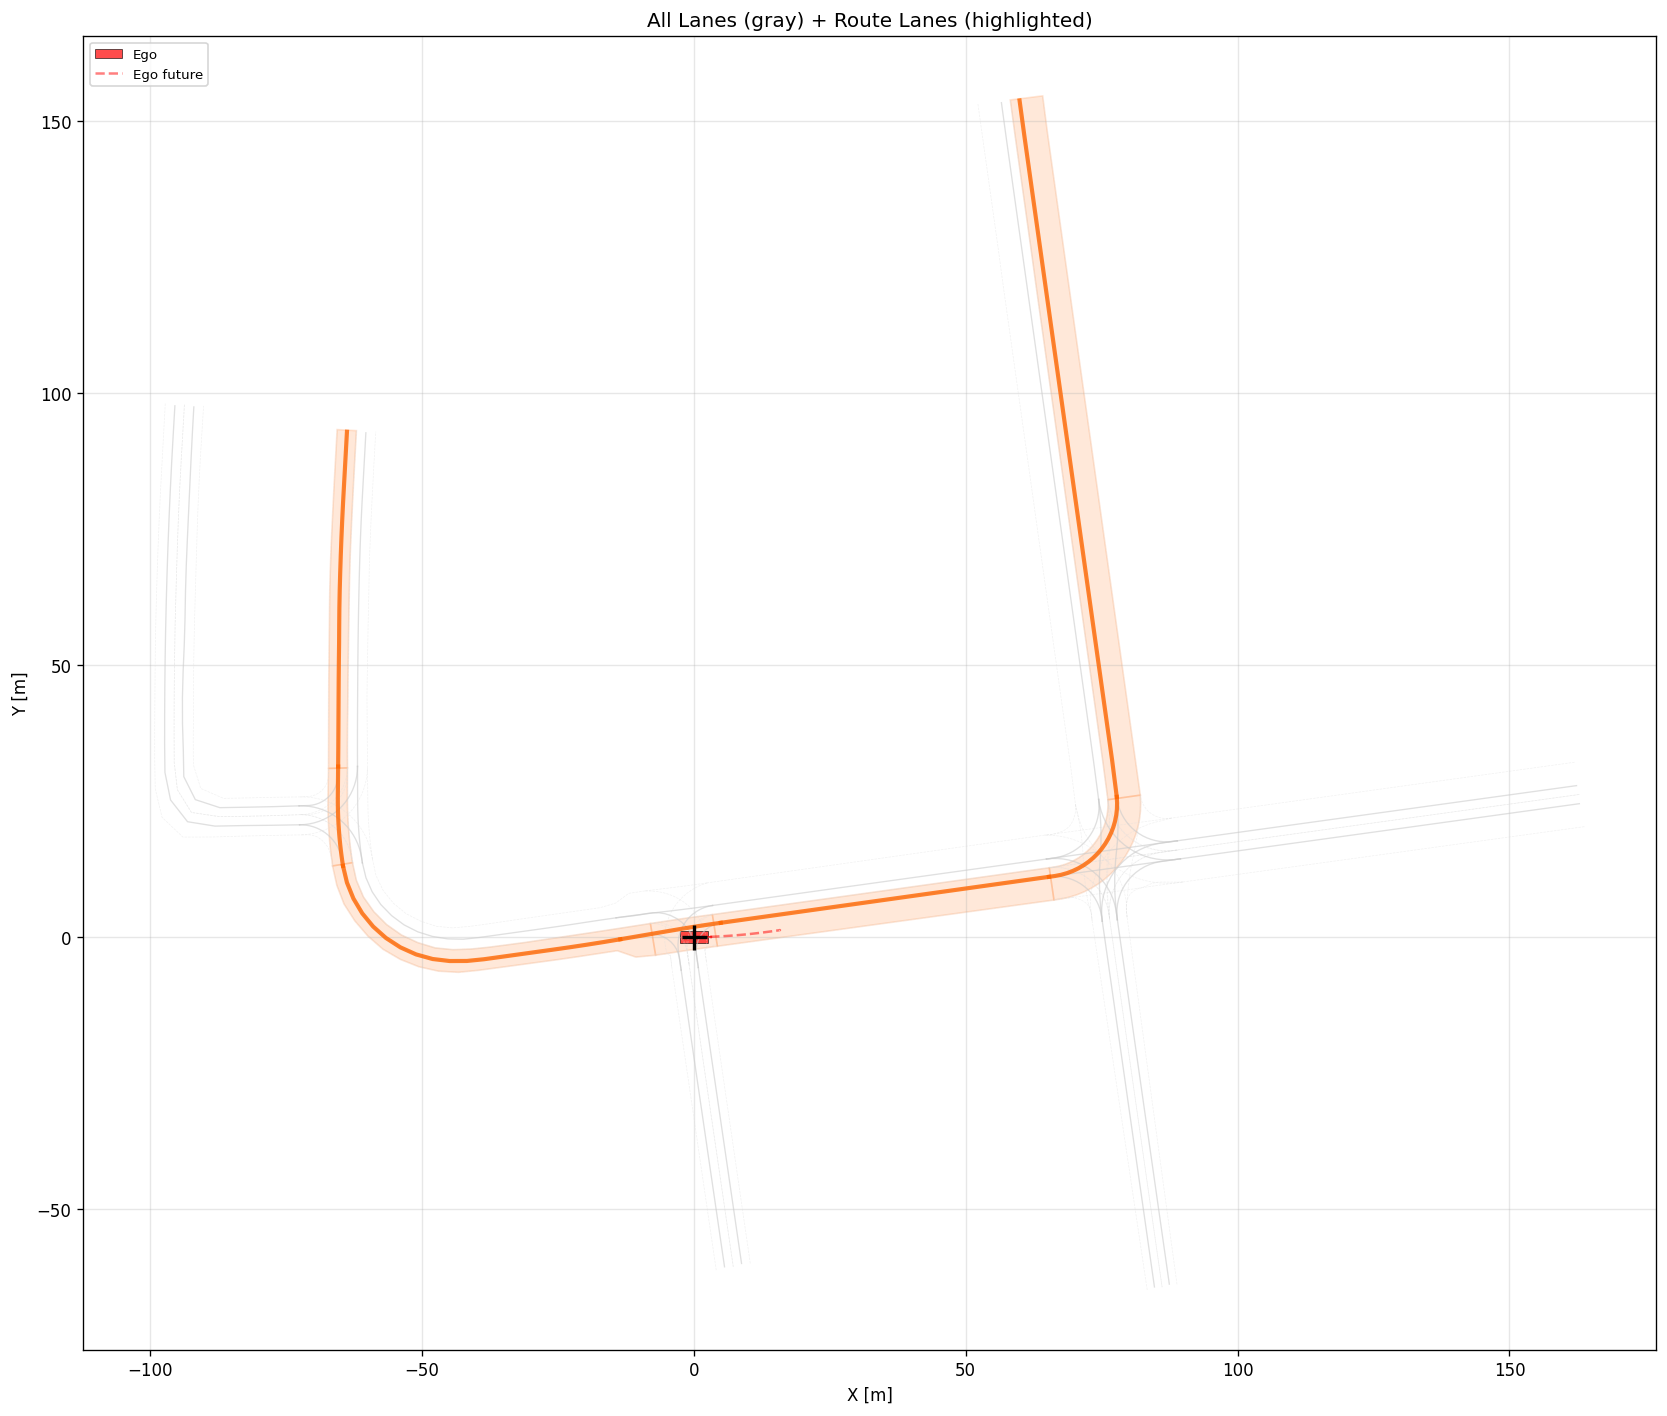

In [82]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('All Lanes (gray) + Route Lanes (highlighted)')

# Background: all lanes in gray
for i in range(lanes.shape[0]):
    lane = lanes[i]
    if not np.any(np.abs(lane) > 1e-6):
        continue
    ax.plot(lane[:, 0], lane[:, 1], '-', color='#cccccc', linewidth=0.8, alpha=0.6)
    left_x = lane[:, 0] + lane[:, 4]
    left_y = lane[:, 1] + lane[:, 5]
    right_x = lane[:, 0] + lane[:, 6]
    right_y = lane[:, 1] + lane[:, 7]
    ax.plot(left_x, left_y, '--', color='#dddddd', linewidth=0.4, alpha=0.4)
    ax.plot(right_x, right_y, '--', color='#dddddd', linewidth=0.4, alpha=0.4)

# Route lanes highlighted
for i in range(route_lanes.shape[0]):
    rl = route_lanes[i]
    if not np.any(np.abs(rl) > 1e-6):
        continue
    ax.plot(rl[:, 0], rl[:, 1], '-', color='#ff6600', linewidth=2.5, alpha=0.8)
    left_x = rl[:, 0] + rl[:, 4]
    left_y = rl[:, 1] + rl[:, 5]
    right_x = rl[:, 0] + rl[:, 6]
    right_y = rl[:, 1] + rl[:, 7]
    ax.fill(np.concatenate([left_x, right_x[::-1]]),
            np.concatenate([left_y, right_y[::-1]]),
            color='#ff6600', alpha=0.15)

# Ego
draw_oriented_box(ax, ego_current[0], ego_current[1],
                  ego_current[2], ego_current[3],
                  ego_current[10], ego_current[11],
                  color='red', alpha=0.7, label='Ego')
ax.plot(ego_future[:, 0], ego_future[:, 1], 'r--', linewidth=1.5, alpha=0.5, label='Ego future')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.legend(fontsize=8, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Static Objects

In [103]:
static_objects = data['static_objects']  # (5, 10) 最大 5 个，不足则 0 填充，按离 ego 距离排序取最近的。

print("=== static_objects ===")
print(f"  Shape: {static_objects.shape}")
print(f"  Dims: x, y, cos_h, sin_h, width, length, type_czone_sign, type_barrier, type_cone, type_generic")
# type_czone_sign	one-hot：施工区标牌
# type_barrier	one-hot：护栏
# type_traffic_cone	one-hot：锥桶
# type_generic	one-hot：其他通用静态物体

STATIC_TYPE_NAMES = ['czone_sign', 'barrier', 'traffic_cone', 'generic']
STATIC_COLORS = ['purple', 'brown', 'orange', 'gray']

for i in range(static_objects.shape[0]):
    so = static_objects[i]
    if np.all(np.abs(so) < 1e-6):
        print(f"  Object {i}: [zero-padded]")
        continue
    type_idx = np.argmax(so[6:10])
    type_name = STATIC_TYPE_NAMES[type_idx]
    print(f"  Object {i}: type={type_name}, pos=({so[0]:.2f}, {so[1]:.2f}), "
          f"size=({so[4]:.2f}x{so[5]:.2f}), heading={np.arctan2(so[3], so[2]):.2f} rad")

=== static_objects ===
  Shape: (5, 10)
  Dims: x, y, cos_h, sin_h, width, length, type_czone_sign, type_barrier, type_cone, type_generic
  Object 0: type=generic, pos=(-47.84, 3.00), size=(0.36x0.38), heading=1.31 rad
  Object 1: [zero-padded]
  Object 2: [zero-padded]
  Object 3: [zero-padded]
  Object 4: [zero-padded]


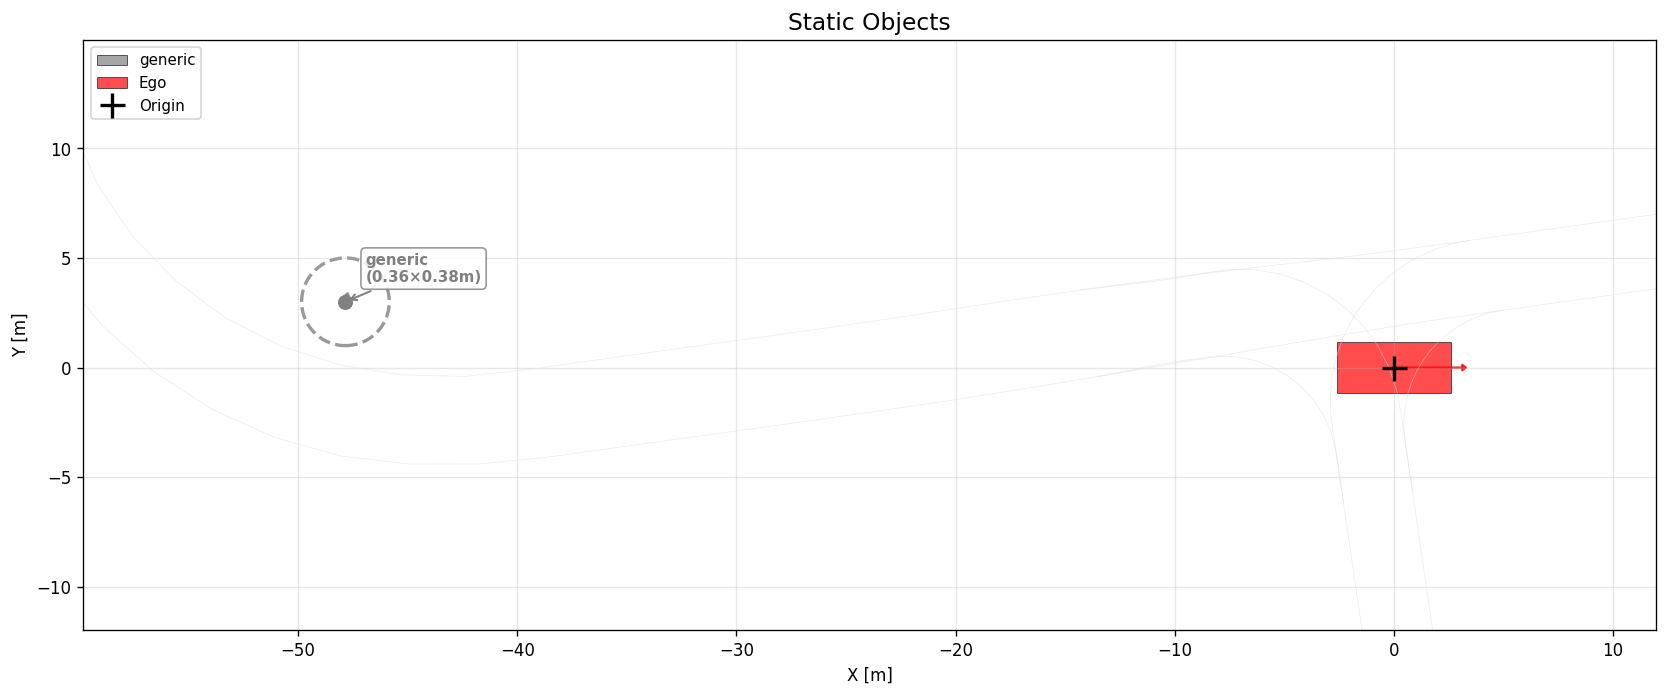

In [105]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('Static Objects', fontsize=14)

# Background lanes
for i in range(lanes.shape[0]):
    lane = lanes[i]
    if np.any(np.abs(lane) > 1e-6):
        ax.plot(lane[:, 0], lane[:, 1], '-', color='#dddddd', linewidth=0.5, alpha=0.5)

all_xs, all_ys = [0.0], [0.0]

legend_added_s = set()
MIN_VISIBLE_SIZE = 2.0  # minimum box size in meters for visibility

for i in range(static_objects.shape[0]):
    so = static_objects[i]
    if np.all(np.abs(so) < 1e-6):
        continue
    type_idx = np.argmax(so[6:10])
    type_name = STATIC_TYPE_NAMES[type_idx]
    color = STATIC_COLORS[type_idx]
    heading = np.arctan2(so[3], so[2])
    lbl = type_name if type_name not in legend_added_s else None

    draw_oriented_box(ax, so[0], so[1], so[2], so[3], so[4], so[5],
                      color=color, alpha=0.7, label=lbl)

    obj_size = max(so[4], so[5])
    if obj_size < MIN_VISIBLE_SIZE:
        circle = plt.Circle((so[0], so[1]), MIN_VISIBLE_SIZE,
                             fill=False, edgecolor=color, linewidth=2, linestyle='--', alpha=0.8)
        ax.add_patch(circle)
        ax.plot(so[0], so[1], marker='o', color=color, markersize=8, zorder=5)

    ax.annotate(f'{type_name}\n({so[4]:.2f}×{so[5]:.2f}m)',
                xy=(so[0], so[1]),
                xytext=(12, 12), textcoords='offset points',
                fontsize=9, color=color, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=color, lw=1.2),
                bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=color, alpha=0.8),
                zorder=10)

    all_xs.append(so[0])
    all_ys.append(so[1])
    legend_added_s.add(type_name)

# Ego
draw_oriented_box(ax, ego_current[0], ego_current[1],
                  ego_current[2], ego_current[3],
                  ego_current[10], ego_current[11],
                  color='red', alpha=0.7, label='Ego')
all_xs.append(ego_current[0])
all_ys.append(ego_current[1])

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='Origin')

# Auto-zoom
margin_ratio = 0.25
x_range = max(all_xs) - min(all_xs)
y_range = max(all_ys) - min(all_ys)
margin = max(10.0, max(x_range, y_range) * margin_ratio)
ax.set_xlim(min(all_xs) - margin, max(all_xs) + margin)
ax.set_ylim(min(all_ys) - margin, max(all_ys) + margin)

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Full Scene Overview

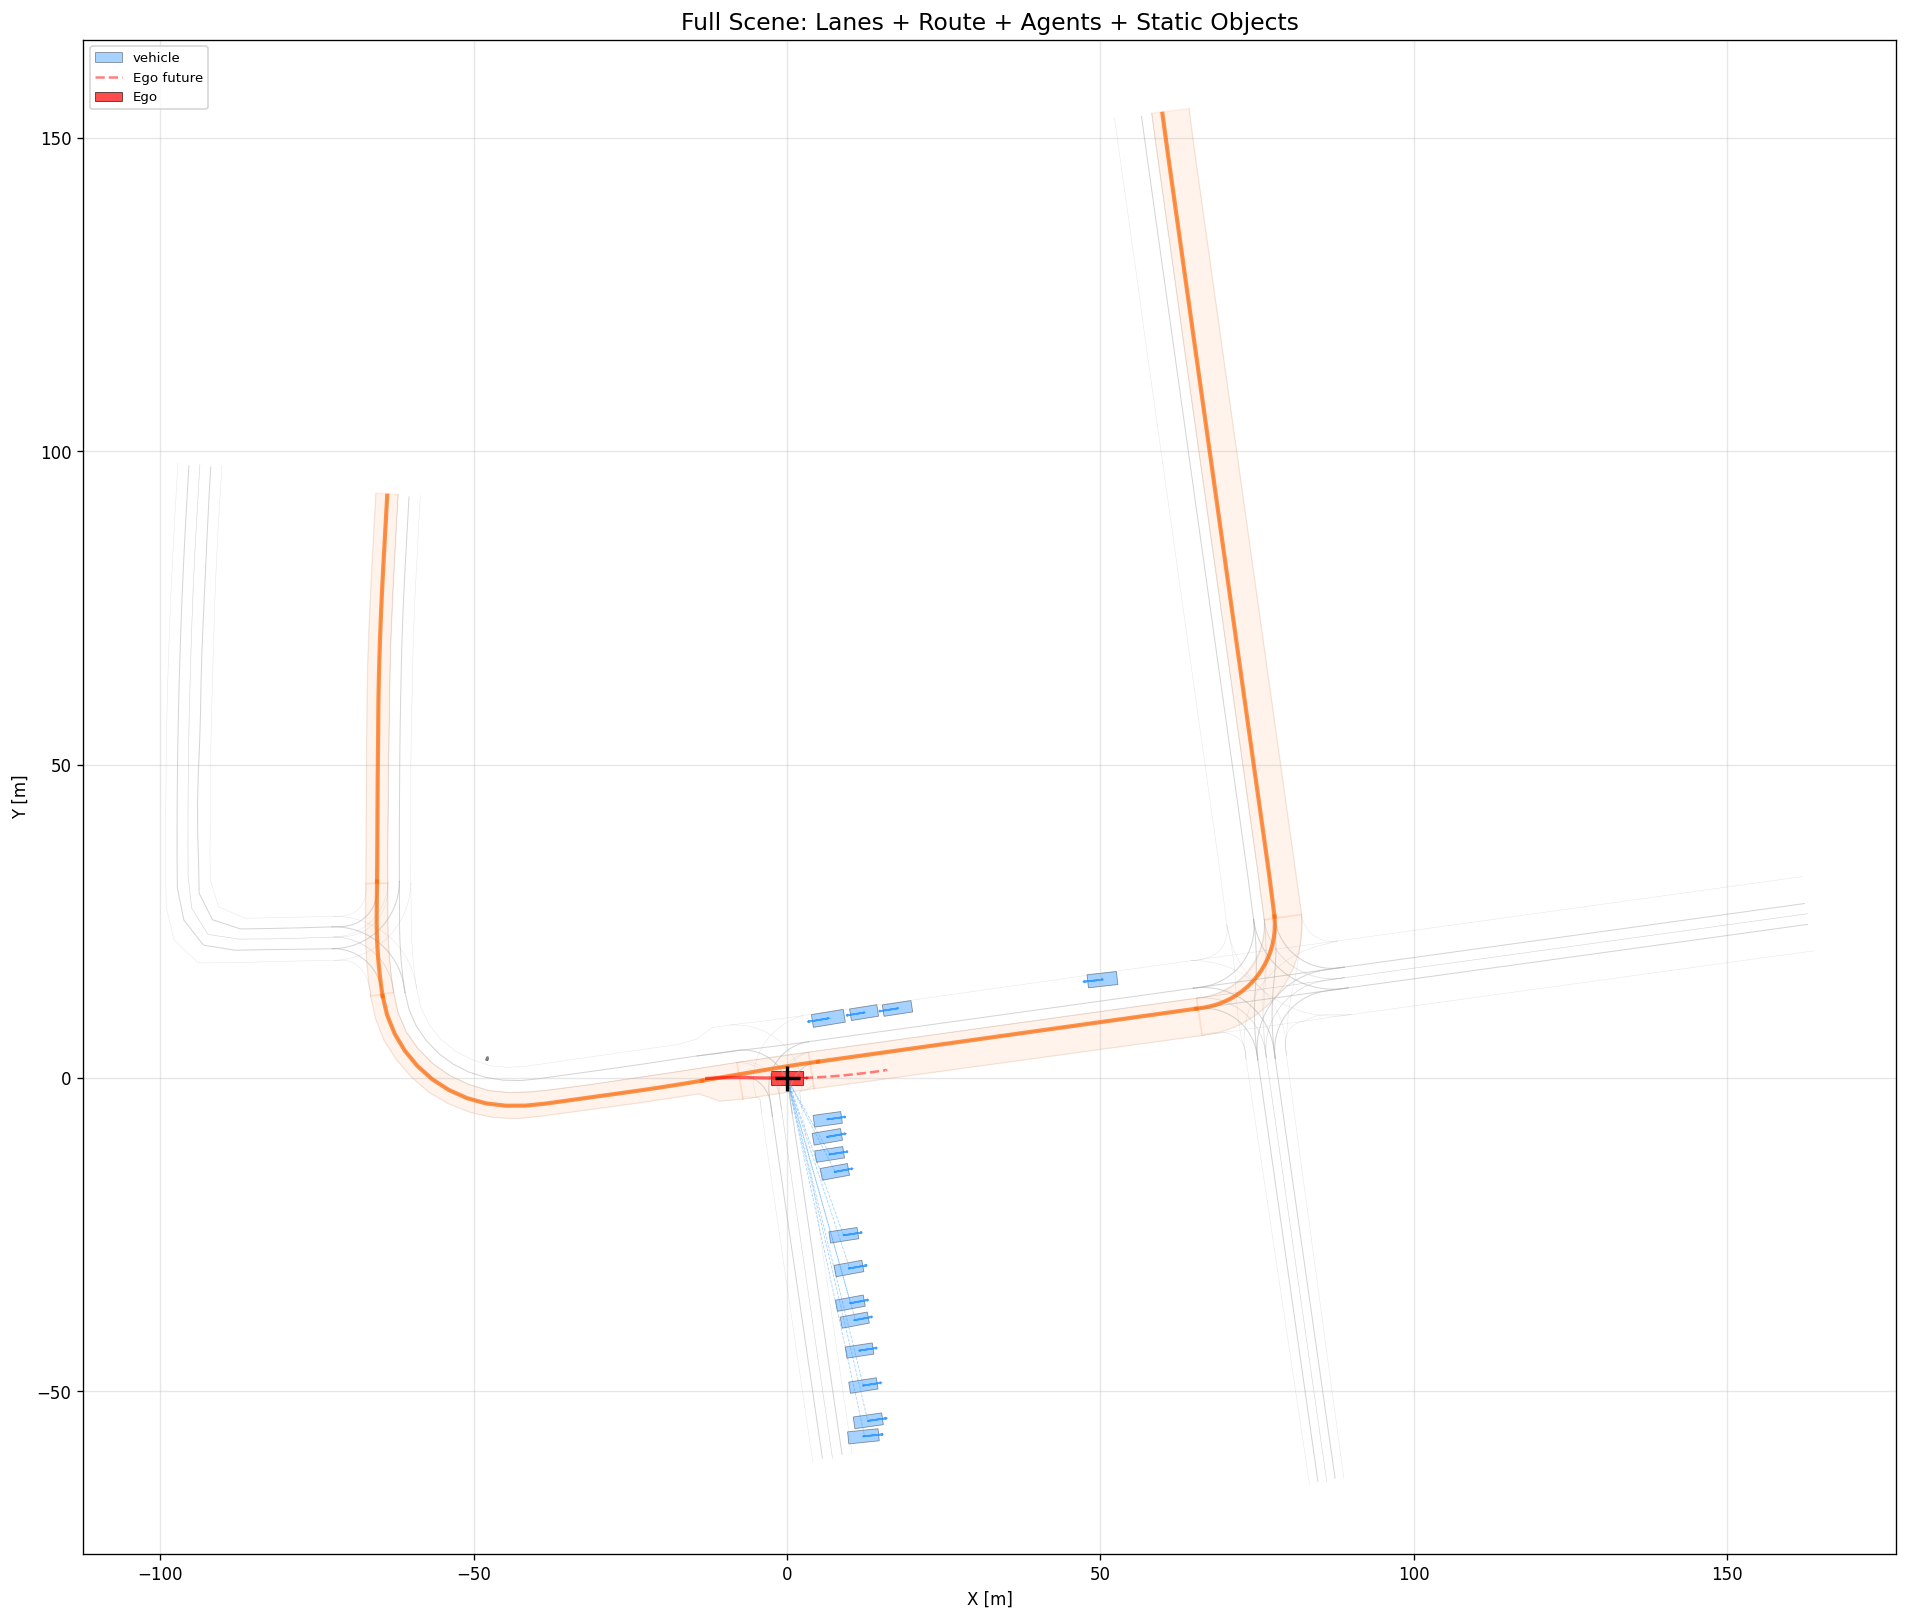

In [85]:
fig, ax = plt.subplots(1, 1, figsize=(16, 16))
ax.set_aspect('equal')
ax.set_title('Full Scene: Lanes + Route + Agents + Static Objects', fontsize=14)

# --- Lanes (background, gray with TL coloring) ---
for i in range(lanes.shape[0]):
    lane = lanes[i]
    if not np.any(np.abs(lane) > 1e-6):
        continue
    tl = lane[0, 8:12]
    if tl[0] > 0.5:
        lc = TL_COLORS['green']; lw = 1.5
    elif tl[1] > 0.5:
        lc = TL_COLORS['yellow']; lw = 1.5
    elif tl[2] > 0.5:
        lc = TL_COLORS['red']; lw = 1.5
    else:
        lc = '#aaaaaa'; lw = 0.6
    ax.plot(lane[:, 0], lane[:, 1], '-', color=lc, linewidth=lw, alpha=0.5)
    # Boundaries
    ax.plot(lane[:, 0] + lane[:, 4], lane[:, 1] + lane[:, 5], '-', color=lc, linewidth=0.3, alpha=0.3)
    ax.plot(lane[:, 0] + lane[:, 6], lane[:, 1] + lane[:, 7], '-', color=lc, linewidth=0.3, alpha=0.3)

# --- Route lanes (highlighted) ---
for i in range(route_lanes.shape[0]):
    rl = route_lanes[i]
    if not np.any(np.abs(rl) > 1e-6):
        continue
    ax.plot(rl[:, 0], rl[:, 1], '-', color='#ff6600', linewidth=2.5, alpha=0.7)
    left_x = rl[:, 0] + rl[:, 4]; left_y = rl[:, 1] + rl[:, 5]
    right_x = rl[:, 0] + rl[:, 6]; right_y = rl[:, 1] + rl[:, 7]
    ax.fill(np.concatenate([left_x, right_x[::-1]]),
            np.concatenate([left_y, right_y[::-1]]),
            color='#ff6600', alpha=0.08)

# --- Neighbor agents ---
legend_added2 = set()
for i in range(neighbor_past.shape[0]):
    if not is_nonzero_agent(neighbor_past[i, -1]):
        continue
    agent_type = get_agent_type_str(neighbor_past[i, -1, 8:11])
    color = AGENT_COLORS[agent_type]
    lbl = f'{agent_type}' if agent_type not in legend_added2 else None
    ax.plot(neighbor_past[i, :, 0], neighbor_past[i, :, 1], '-', color=color, linewidth=0.8, alpha=0.5)
    cur = neighbor_past[i, -1]
    draw_oriented_box(ax, cur[0], cur[1], cur[2], cur[3], cur[6], cur[7],
                      color=color, alpha=0.4, label=lbl)
    if is_nonzero_agent(neighbor_future[i, 0]):
        ax.plot(neighbor_future[i, :, 0], neighbor_future[i, :, 1], '--',
                color=color, linewidth=0.5, alpha=0.4)
    legend_added2.add(agent_type)

# --- Static objects ---
for i in range(static_objects.shape[0]):
    so = static_objects[i]
    if np.all(np.abs(so) < 1e-6):
        continue
    type_idx = np.argmax(so[6:10])
    draw_oriented_box(ax, so[0], so[1], so[2], so[3], so[4], so[5],
                      color=STATIC_COLORS[type_idx], alpha=0.6)

# --- Ego ---
ax.plot(ego_past[:, 0], ego_past[:, 1], 'r-', linewidth=2, alpha=0.6)
ax.plot(ego_future[:, 0], ego_future[:, 1], 'r--', linewidth=1.5, alpha=0.5, label='Ego future')
draw_oriented_box(ax, ego_current[0], ego_current[1],
                  ego_current[2], ego_current[3],
                  ego_current[10], ego_current[11],
                  color='red', alpha=0.7, label='Ego')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.legend(fontsize=8, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Detailed Verification Checks

Run automated checks to confirm the data semantics match our expectations.

In [86]:
print("=" * 60)
print("AUTOMATED VERIFICATION CHECKS")
print("=" * 60)

# Check 1: Ego current position near origin
ego_dist = np.sqrt(ego_current[0]**2 + ego_current[1]**2)
check1 = ego_dist < 5.0  # should be very close to origin
print(f"\n[{'PASS' if check1 else 'FAIL'}] Ego current near origin: dist={ego_dist:.4f} m")

# Check 2: cos_h^2 + sin_h^2 == 1 for ego
heading_norm = np.sqrt(ego_current[2]**2 + ego_current[3]**2)
check2 = abs(heading_norm - 1.0) < 0.01
print(f"[{'PASS' if check2 else 'FAIL'}] Ego heading unit vector: |cos_h, sin_h| = {heading_norm:.6f}")

# Check 3: lanes direction vectors (dx, dy) are forward differences
check3_ok = True
for i in range(lanes.shape[0]):
    lane = lanes[i]
    if not np.any(np.abs(lane) > 1e-6):
        continue
    # dx, dy should approximate (point[j+1] - point[j])
    for j in range(lane.shape[0] - 2):  # skip last point where dx,dy=0
        actual_dx = lane[j+1, 0] - lane[j, 0]
        actual_dy = lane[j+1, 1] - lane[j, 1]
        stored_dx = lane[j, 2]
        stored_dy = lane[j, 3]
        if abs(actual_dx) + abs(actual_dy) > 1e-6:
            err = np.sqrt((actual_dx - stored_dx)**2 + (actual_dy - stored_dy)**2)
            if err > 0.5:  # allow some tolerance
                check3_ok = False
                break
    if not check3_ok:
        break
print(f"[{'PASS' if check3_ok else 'FAIL'}] Lane direction vectors = forward differences")

# Check 4: Boundary offsets are relative (not absolute)
check4_ok = True
for i in range(lanes.shape[0]):
    lane = lanes[i]
    if not np.any(np.abs(lane) > 1e-6):
        continue
    left_offset_mag = np.sqrt(lane[:, 4]**2 + lane[:, 5]**2).mean()
    right_offset_mag = np.sqrt(lane[:, 6]**2 + lane[:, 7]**2).mean()
    # Offsets should be small (a few meters) if they're relative to center
    if left_offset_mag > 20 or right_offset_mag > 20:
        check4_ok = False
        break
print(f"[{'PASS' if check4_ok else 'FAIL'}] Lane boundary dims are offsets (small magnitude)")

# Check 5: Traffic light one-hot: at most one bit set per point
check5_ok = True
for i in range(lanes.shape[0]):
    lane = lanes[i]
    if not np.any(np.abs(lane) > 1e-6):
        continue
    tl_sum = lane[:, 8:12].sum(axis=-1)
    if np.any(tl_sum > 1.1):  # should be 0 or 1
        check5_ok = False
        break
print(f"[{'PASS' if check5_ok else 'FAIL'}] Traffic light encoding is valid one-hot")

# Check 6: TL encoding order - print the encoding for a lane with traffic light
for i in range(lanes.shape[0]):
    tl = lanes[i, 0, 8:12]
    if np.any(tl > 0.5):
        idx = np.argmax(tl)
        names = ['green', 'yellow', 'red', 'unknown']
        print(f"  Sample TL lane {i}: encoding={tl}, state={names[idx]}")
        break

# Check 7: Agent type one-hot
check7_ok = True
for i in range(neighbor_past.shape[0]):
    if not is_nonzero_agent(neighbor_past[i, -1]):
        continue
    type_sum = neighbor_past[i, -1, 8:11].sum()
    if abs(type_sum - 1.0) > 0.1:
        check7_ok = False
        print(f"  Agent {i} type one-hot sum = {type_sum}")
        break
print(f"[{'PASS' if check7_ok else 'FAIL'}] Neighbor agent type encoding is valid one-hot")

# Check 8: ego_agent_past dimensions
check8 = ego_past.shape == (21, 14)
print(f"[{'PASS' if check8 else 'FAIL'}] ego_agent_past shape = {ego_past.shape} (expected (21, 14))")

# Check 9: ego_current_state dimensions
check9 = ego_current.shape == (16,)
print(f"[{'PASS' if check9 else 'FAIL'}] ego_current_state shape = {ego_current.shape} (expected (16,))")

# Check 10: ego_agent_future dimensions
check10 = ego_future.shape[1] == 3
print(f"[{'PASS' if check10 else 'FAIL'}] ego_agent_future shape = {ego_future.shape} (expected (80, 3))")

print("\n" + "=" * 60)
all_checks = [check1, check2, check3_ok, check4_ok, check5_ok, check7_ok, check8, check9, check10]
print(f"Result: {sum(all_checks)}/{len(all_checks)} checks passed.")
print("=" * 60)

AUTOMATED VERIFICATION CHECKS

[PASS] Ego current near origin: dist=0.0000 m
[PASS] Ego heading unit vector: |cos_h, sin_h| = 1.000000
[PASS] Lane direction vectors = forward differences
[PASS] Lane boundary dims are offsets (small magnitude)
[PASS] Traffic light encoding is valid one-hot
  Sample TL lane 0: encoding=[0. 0. 0. 1.], state=unknown
[PASS] Neighbor agent type encoding is valid one-hot
[PASS] ego_agent_past shape = (21, 14) (expected (21, 14))
[PASS] ego_current_state shape = (16,) (expected (16,))
[PASS] ego_agent_future shape = (80, 3) (expected (80, 3))

Result: 9/9 checks passed.
